# Fertility (clasificación)

**Autores:** Eduardo Estefanía Ovejero y Guillem Alcubilla Pueyo 

Origen de los datos: https://archive.ics.uci.edu/dataset/244/fertility

Cargar las librerías para el proyecto

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler


from ucimlrepo import fetch_ucirepo
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

from sklearn.feature_selection import chi2, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

Descargar el dataset

In [2]:
# fetch dataset 
fertility = fetch_ucirepo(id=244) 
  
# data (as pandas dataframes) 
X = fertility.data.features 
y = fertility.data.targets 
  
# metadata 
print(fertility.metadata) 
  
# variable information 
print(fertility.variables) 

{'uci_id': 244, 'name': 'Fertility', 'repository_url': 'https://archive.ics.uci.edu/dataset/244/fertility', 'data_url': 'https://archive.ics.uci.edu/static/public/244/data.csv', 'abstract': '100 volunteers provide a semen sample analyzed according to the WHO 2010 criteria. Sperm concentration are related to socio-demographic data, environmental factors, health status, and life habits', 'area': 'Health and Medicine', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 100, 'num_features': 9, 'feature_types': ['Real'], 'demographics': ['Age'], 'target_col': ['diagnosis'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2012, 'last_updated': 'Fri Mar 15 2024', 'dataset_doi': '10.24432/C5Z01Z', 'creators': ['David Gil', 'Jose Girela'], 'intro_paper': {'ID': 429, 'type': 'NATIVE', 'title': 'Predicting seminal quality with artificial intelligence methods', 'authors': 'David Gil, J. L. Girel

In [3]:
import os

# Ruta al dataset (compatible ejecutando desde 'notebooks/' o desde la raíz)
DATA_PATH = '../data/raw/fertility_Diagnosis.txt' if os.path.exists('../data/raw/fertility_Diagnosis.txt') else 'data/raw/fertility_Diagnosis.txt'
df_provisional = pd.read_csv(DATA_PATH)
X = df_provisional.drop('diagnosis', axis=1)
y = df_provisional['diagnosis']


## 1. Preprocesado

In [4]:
X.head()

,season,age,child_diseases,accident,surgical_intervention,high_fevers,alcohol,smoking,hrs_sitting
0,-0.33,0.69,0,1,1,0,0.8,0,0.88
1,-0.33,0.94,1,0,1,0,0.8,1,0.31
2,-0.33,0.50,1,0,0,0,1.0,-1,0.50
3,-0.33,0.75,0,1,1,0,1.0,-1,0.38
4,-0.33,0.67,1,1,0,0,0.8,-1,0.50


In [5]:
y.head()

0    N
1    O
2    N
3    N
4    O
Name: diagnosis, dtype: object

In [6]:
# Reemplazar 'N' por 0 y 'O' por 1
y = y.replace({'N': 0, 'O': 1}) 
y.head()

0    0
1    1
2    0
3    0
4    1
Name: diagnosis, dtype: int64

In [7]:
df_full = X.copy()
df_full['target'] = y
print(df_full.duplicated().sum())

0


In [8]:
import os

# Guardar dataset preprocesado en data/processed/
output_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
os.makedirs(output_dir, exist_ok=True)
df_full.to_csv(os.path.join(output_dir, 'fertility_Diagnosis_Preprocesado.csv'), index=False)
print('Dataset guardado correctamente.')


Dataset guardado correctamente.


In [9]:
# Variables numéricas continuas
num_cols = [col for col in X.columns if X[col].nunique() > 10 and np.issubdtype(X[col].dtype, np.number)]
# Variables categóricas o binarias
cat_cols = [col for col in X.columns if col not in num_cols]

print("Variables numéricas continuas:", num_cols)
print("Variables categóricas o binarias:", cat_cols)

Variables numéricas continuas: ['age', 'hrs_sitting']
Variables categóricas o binarias: ['season', 'child_diseases', 'accident', 'surgical_intervention', 'high_fevers', 'alcohol', 'smoking']


In [10]:
X.describe()

,season,age,child_diseases,accident,surgical_intervention,high_fevers,alcohol,smoking,hrs_sitting
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,-0.078900,0.669000,0.870000,0.440000,0.510000,0.190000,0.832000,-0.350000,0.406800
std,0.796725,0.121319,0.337998,0.498888,0.502418,0.580752,0.167501,0.808728,0.186395
min,-1.000000,0.500000,0.000000,0.000000,0.000000,-1.000000,0.200000,-1.000000,0.060000
25%,-1.000000,0.560000,1.000000,0.000000,0.000000,0.000000,0.800000,-1.000000,0.250000
50%,-0.330000,0.670000,1.000000,0.000000,1.000000,0.000000,0.800000,-1.000000,0.380000
75%,1.000000,0.750000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.500000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Selección de variables

In [11]:
f_stats, p_values_anova = f_classif(X[num_cols], y)

anova_results = pd.DataFrame({
    'Variable': num_cols,
    'Test': 'ANOVA',
    'Estadístico': f_stats,
    'P-Valor': p_values_anova
})

scaler = MinMaxScaler()
X_cat_scaled = scaler.fit_transform(X[cat_cols])

# Calculamos chi2 con los datos escalados positivamente
chi_stats, p_values_chi = chi2(X_cat_scaled, y)

chi_results = pd.DataFrame({
    'Variable': cat_cols,
    'Test': 'Chi-cuadrado',
    'Estadístico': chi_stats,
    'P-Valor': p_values_chi
})

# --- 4. Unir y mostrar los resultados ---
# Concatenamos ambos dataframes y los ordenamos por el p-valor de menor a mayor
feature_selection_results = pd.concat([anova_results, chi_results]).sort_values(by='P-Valor')

# Reiniciar el índice para que se vea limpio
feature_selection_results = feature_selection_results.reset_index(drop=True)

print("--- Resultados de Selección de Características ---")
print(feature_selection_results)

--- Resultados de Selección de Características ---
                Variable          Test  Estadístico   P-Valor
0                    age         ANOVA     1.318727  0.253616
1                 season  Chi-cuadrado     1.262996  0.261085
2               accident  Chi-cuadrado     1.118802  0.290177
3            high_fevers  Chi-cuadrado     0.206837  0.649258
4  surgical_intervention  Chi-cuadrado     0.143791  0.704541
5                alcohol  Chi-cuadrado     0.115123  0.734386
6                smoking  Chi-cuadrado     0.104895  0.746033
7            hrs_sitting         ANOVA     0.051708  0.820591
8         child_diseases  Chi-cuadrado     0.021073  0.884581


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

## 2. Visualización

In [13]:
print("\n=== INFORMACIÓN DEL DATASET ===")
print(f"Dimensiones de X: {X.shape}")
print(f"Distribución de clases:\n{y.value_counts().sort_index()}")


=== INFORMACIÓN DEL DATASET ===
Dimensiones de X: (100, 9)
Distribución de clases:
diagnosis
0    88
1    12
Name: count, dtype: int64


### 2.1 Diagramas de cajas

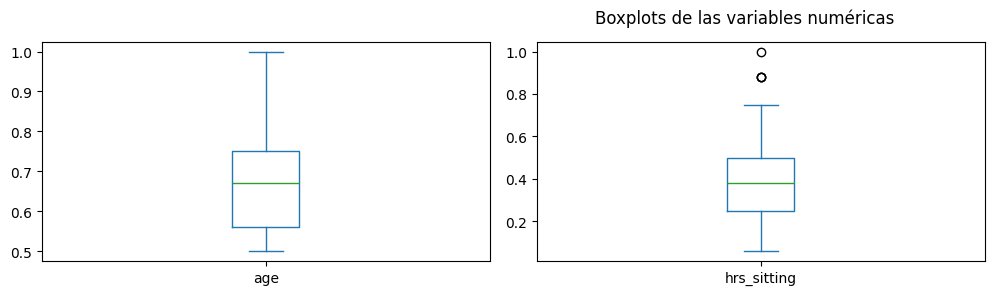

In [14]:
X[num_cols].plot(kind='box', subplots=True, layout=(int(np.ceil(len(X.columns)/3)), 3), figsize=(15, 8), sharex=False, sharey=False)
plt.suptitle("Boxplots de las variables numéricas")
plt.tight_layout()
plt.show()

### 2.2 Diagramas de Dispersión

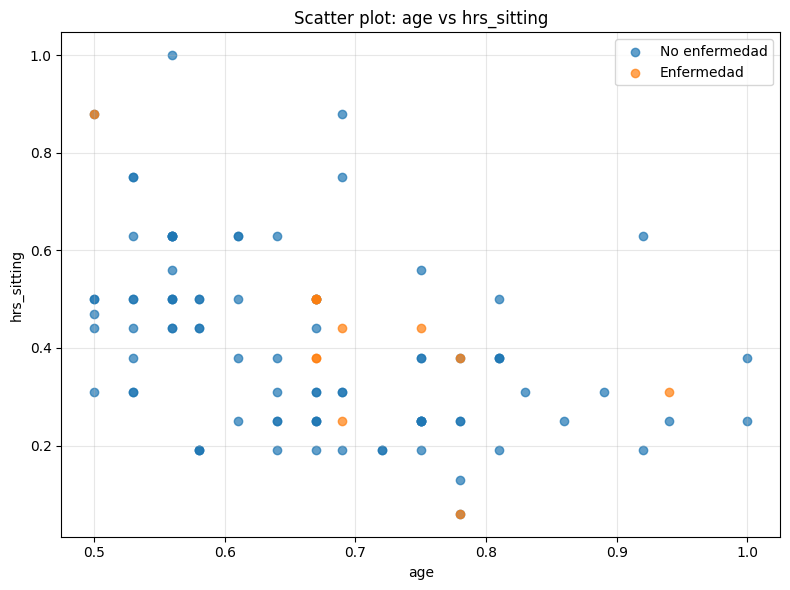

In [15]:
df_viz = X.copy()
df_viz["target"] = y

preferred_pairs = [
    ("age", "thalach"),
    ("age", "chol"),
    ("trestbps", "chol")
]

x_col, y_col = None, None
for c1, c2 in preferred_pairs:
    if c1 in num_cols and c2 in num_cols:
        x_col, y_col = c1, c2
        break

# Si no existen esas variables, usar las dos primeras numéricas
if x_col is None or y_col is None:
    if len(num_cols) >= 2:
        x_col, y_col = num_cols[0], num_cols[1]

if x_col is not None and y_col is not None:
    plt.figure(figsize=(8, 6))

    scatter_mask = df_viz[x_col].notna() & df_viz[y_col].notna()

    clase_0 = df_viz.loc[scatter_mask & (df_viz["target"] == 0)]
    clase_1 = df_viz.loc[scatter_mask & (df_viz["target"] == 1)]

    plt.scatter(clase_0[x_col], clase_0[y_col], alpha=0.7, label="No enfermedad")
    plt.scatter(clase_1[x_col], clase_1[y_col], alpha=0.7, label="Enfermedad")

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.title(f"Scatter plot: {x_col} vs {y_col}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### 2.3 Diagramas de Barras e Histogramas

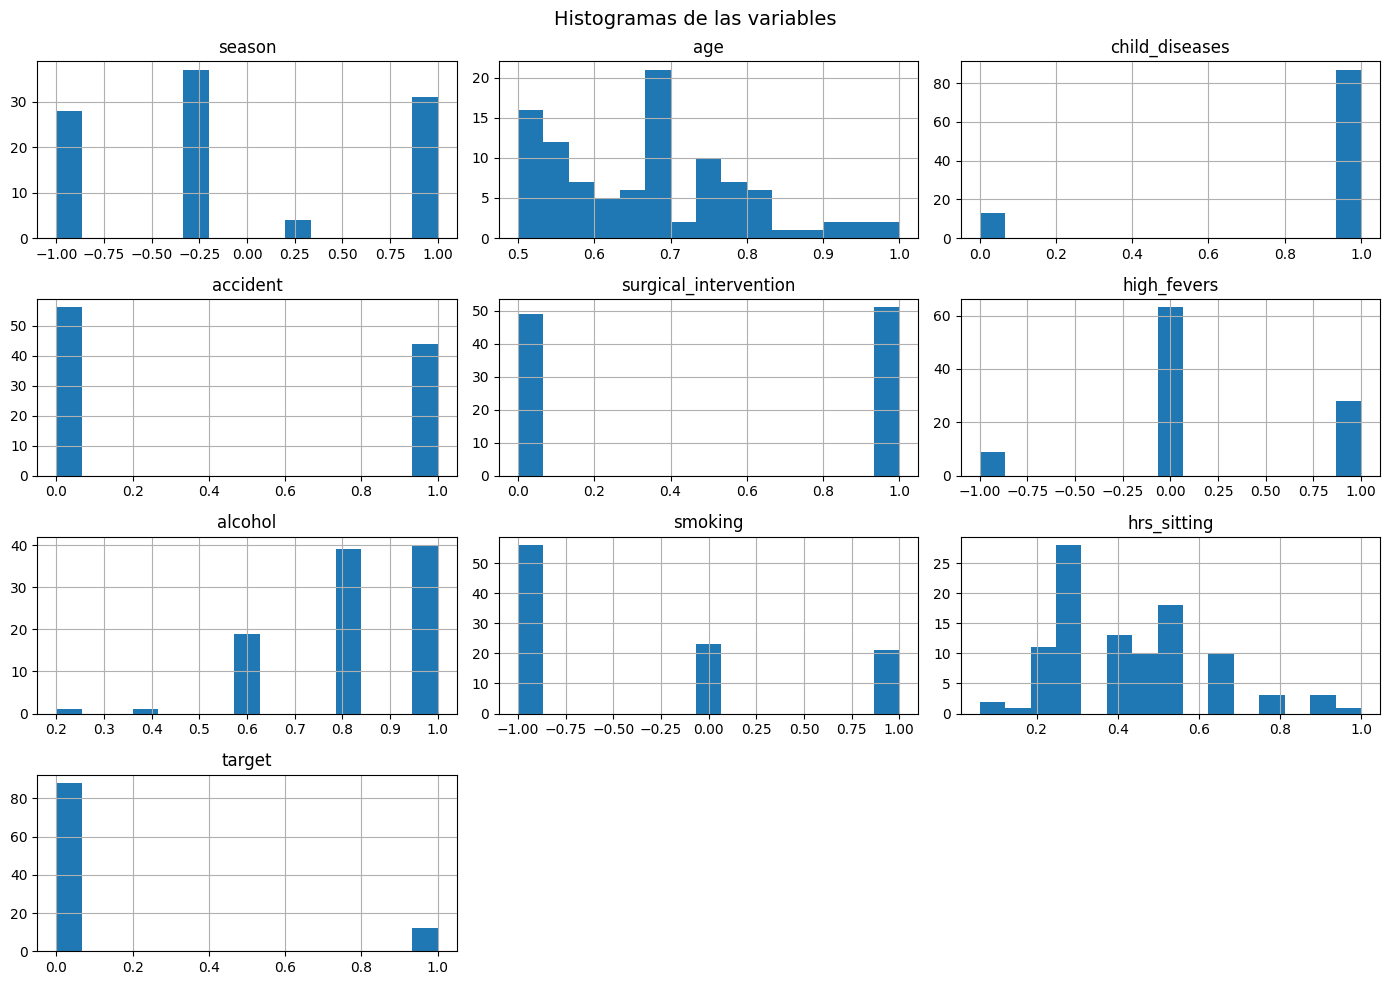

In [16]:
df_full.hist(figsize=(14, 10), bins=15)
plt.suptitle("Histogramas de las variables", fontsize=14)
plt.tight_layout()
plt.show()

### 2.4 Matriz de correlación

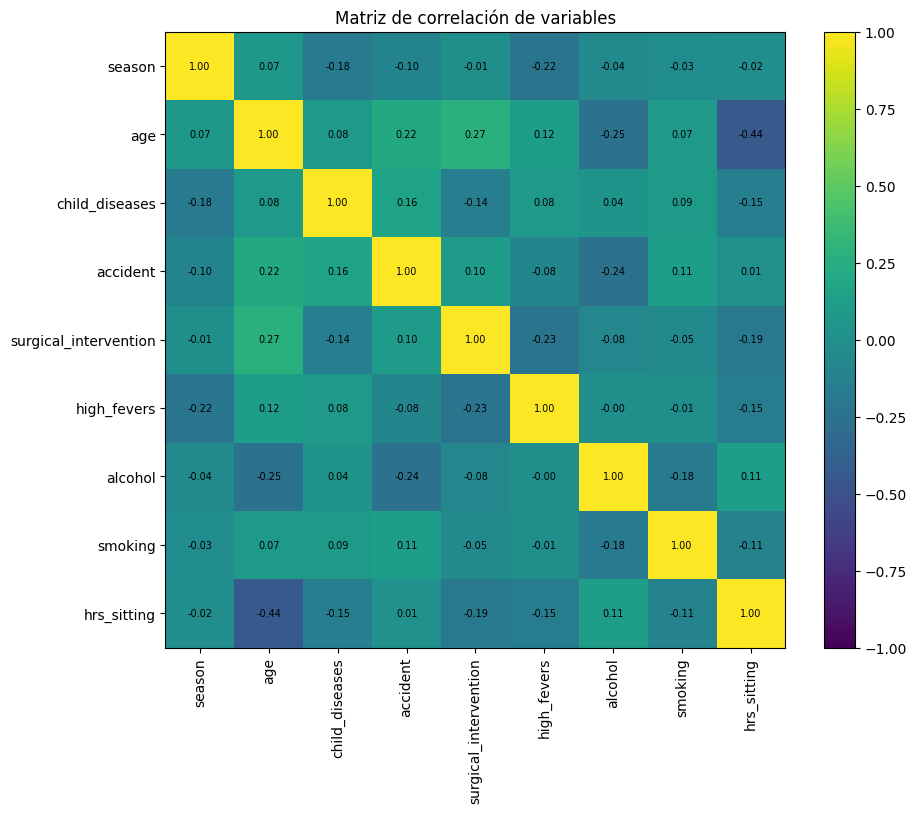

In [17]:
corr_matrix = X.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
im = plt.imshow(corr_matrix, interpolation="nearest", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(im)

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

plt.title("Matriz de correlación de variables")

# Anotar los valores de correlación dentro de la matriz
for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        plt.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

## 3. Entrenamiento

MODELO DE LA RED NEURONAL

In [18]:
# =========================================================
# 3. MODELO MLP (MODO AGRESIVO PARA DATASET PEQUEÑO)
# =========================================================
modelo = ImbPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    # Bajamos los vecinos porque tenemos poquísimos casos reales
    ("undersampler", RandomUnderSampler(random_state=42)),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(10, 5),    # Le damos un poco más de "cerebro"
        activation="relu",
        solver="adam",
        alpha=1e-5,                    # Reducimos la regularización para que se arriesgue más
        batch_size=16,                 # Lotes más pequeños = actualizaciones de pesos más agresivas
        learning_rate_init=0.005,      # Tasa de aprendizaje un poco más alta
        max_iter=500,                  # Le damos mucho más tiempo para aprender
        early_stopping=False,          # ¡APAGADO! Que entrene con el 100% de los datos de train
        random_state=42
    ))
])

DIVISIÓN DEL DATASET K-FOLD


=== RESULTADOS VALIDACIÓN CRUZADA (10-FOLD) ===
ACCURACY  : 0.5000 ± 0.1581
PRECISION : 0.1402 ± 0.0997
RECALL    : 0.7000 ± 0.4583
F1        : 0.2319 ± 0.1612
ROC_AUC   : 0.4429 ± 0.2959

=== EVALUACIÓN ENTRENAMIENTO ===
Accuracy: 0.5000
ROC AUC:  0.4929

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.47      0.62        70
           1       0.16      0.70      0.26        10

    accuracy                           0.50        80
   macro avg       0.54      0.59      0.44        80
weighted avg       0.82      0.50      0.58        80



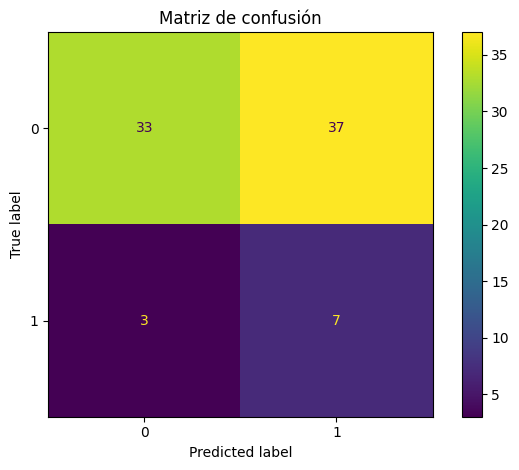

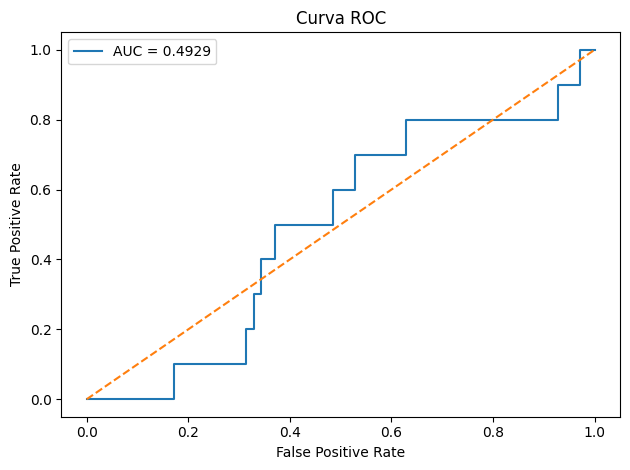

In [19]:
# =========================================================
# 4. VALIDACIÓN CRUZADA K-FOLD = 10
# =========================================================
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    modelo,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

print("\n=== RESULTADOS VALIDACIÓN CRUZADA (10-FOLD) ===")
for metric in scoring.keys():
    scores = cv_results[f"test_{metric}"]
    print(f"{metric.upper():10s}: {scores.mean():.4f} ± {scores.std():.4f}")

# Predicciones globales usando CV
y_pred = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict", n_jobs=-1)
y_prob = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

# =========================================================
# 5. EVALUACIÓN
# =========================================================
acc = accuracy_score(y_train, y_pred)
auc = roc_auc_score(y_train, y_prob)

print("\n=== EVALUACIÓN ENTRENAMIENTO ===")
print(f"Accuracy: {acc:.4f}")
print(f"ROC AUC:  {auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_train, y_pred))

cm = confusion_matrix(y_train, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_train, y_prob)
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
modelo.fit(X_train, y_train)

mlp_final = modelo.named_steps["mlp"]
print("\n=== RED ENTRENADA FINAL ===")
print("Capas ocultas:", mlp_final.hidden_layer_sizes)
print("Activación:", mlp_final.activation)
print("Número total de capas:", mlp_final.n_layers_)
print("Tamaño de la capa de salida:", mlp_final.n_outputs_)


=== RED ENTRENADA FINAL ===
Capas ocultas: (10, 5)
Activación: relu
Número total de capas: 4
Tamaño de la capa de salida: 1



=== EVALUACIÓN EN TEST ===
Accuracy Test: 0.5500

Reporte de Clasificación Test:
              precision    recall  f1-score   support

           0       0.91      0.56      0.69        18
           1       0.11      0.50      0.18         2

    accuracy                           0.55        20
   macro avg       0.51      0.53      0.44        20
weighted avg       0.83      0.55      0.64        20



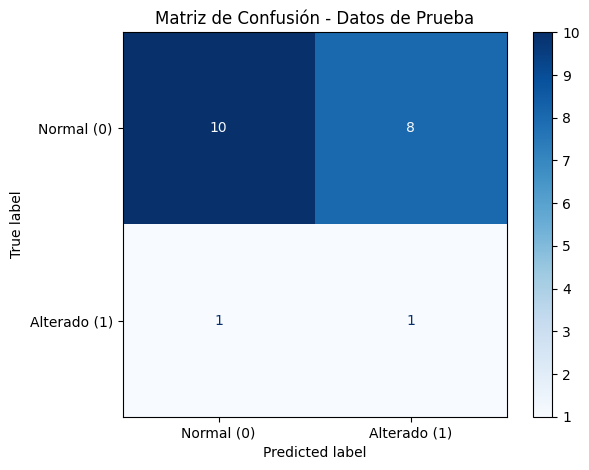

In [21]:
# =========================================================
# 6. EVALUACIÓN FINAL EN CONJUNTO DE PRUEBA (TEST)
# =========================================================

# 1. Hacer que la red prediga sobre los datos que NUNCA ha visto
y_pred_test = modelo.predict(X_test)
y_prob_test = modelo.predict_proba(X_test)[:, 1] # Probabilidades para la curva ROC si la necesitas

# 2. Calcular la precisión real
acc_test = accuracy_score(y_test, y_pred_test)

print("\n=== EVALUACIÓN EN TEST ===")
print(f"Accuracy Test: {acc_test:.4f}")
print("\nReporte de Clasificación Test:")
print(classification_report(y_test, y_pred_test))

# 3. Dibujar la matriz de confusión definitiva
cm_test = confusion_matrix(y_test, y_pred_test)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['Normal (0)', 'Alterado (1)'])
disp_test.plot(cmap='Blues')
plt.title("Matriz de Confusión - Datos de Prueba")
plt.tight_layout()
plt.show()